# Exploração dos Dados

## Importação de Bibliotecas Necessárias

In [1]:
# Importar pacotes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder,  MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer

## Importação das Planilhas de Dados

In [2]:
# Carregar os arquivos CSV

# Carregamento direto e completo

# df_gf = pd.read_csv("/content/Grupo com registro entre 07-2024 a 06-2025- GF.csv", sep="\t", header=0, engine="python")
# df_gl = pd.read_csv("/content/Grupo com registro entre 07-2024 a 06-2025- GL.csv", sep="\t", header=0, engine="python")
# df_gm = pd.read_csv("/content/Grupo com registro entre 07-2024 a 06-2025- GM.csv", sep="\t", header=0, engine="python")
# df_gp = pd.read_csv("/content/Grupo com registro entre 07-2024 a 06-2025- GP.csv", sep="\t", header=0, engine="python")
# df_gt = pd.read_csv("/content/Grupo com registro entre 07-2024 a 06-2025- GT.csv", sep="\t", header=0, engine="python")
# df_gv = pd.read_csv("/content/Grupo com registro entre 07-2024 a 06-2025- GV.csv", sep="\t", header=0, engine="python")
# df_gw = pd.read_csv("/content/Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep="\t", header=0, engine="python")

# Carregamento em amostras para economia de memória e testes

df_gf = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GF.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gl = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GL.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gm = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GM.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gp = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GP.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gt = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GT.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gv = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GV.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gw = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)

# Após carregar, conversão de floats para float32 para economizar memória também

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in df.select_dtypes(include="float64").columns:
        df[col] = df[col].astype("float32")


 ## Divisão de Colunas em Múltiplas Colunas

In [3]:
# Função para a divisão das colunas

def dividir_colunas(df):

    # Verifica se o DataFrame tem apenas uma coluna.

    if df.shape[1] == 1:

        # Divide a única coluna em múltiplas colunas.

        dados = df.iloc[:, 0].str.split('\t', expand=True)

        # Usa a primeira linha como nomes das colunas.

        dados.columns = dados.iloc[0]

        # Remove a primeira linha por ter virado cabeçalho.

        dados = dados.drop(index=0).reset_index(drop=True)
        return dados
    else:

        return df

df_gf = dividir_colunas(df_gf)
df_gl = dividir_colunas(df_gl)
df_gm = dividir_colunas(df_gm)
df_gp = dividir_colunas(df_gp)
df_gt = dividir_colunas(df_gt)
df_gv = dividir_colunas(df_gv)
df_gw = dividir_colunas(df_gw)

## Conversão de Tipos de Dados

In [4]:
# Divisão de tipos

colunas_numericas = ['id_grupo', 'id_pagador', 'id_beneficiario', 'Numero_do_boleto', 'vl_boleto', 'vl_pagto', 'juros']
colunas_categoricas = ['status_boleto', 'pagador_cep', 'banco', 'tipo_juros', 'pagador_cidade']
colunas_data = ['data_inclusao', 'data_vencto', 'dt_pagto']
colunas_texto = [ 'pagador_cep', 'pagador_cnpjcpf', 'pagador_inscricao_hash']

# Função para converter em um DataFrame

def converter_tipos(df):

    # Converte colunas numéricas para tipo numérico, formatando '\N' como NaN

    for col in colunas_numericas:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')

    # Converte colunas categóricas para category

    for col in colunas_categoricas:
        if col in df.columns:
            df[col] = df[col].astype('category')

    # Converte colunas de data para tipo datetime, formatando '\N' como NaN

    for col in colunas_data:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col].replace('\\N', np.nan), errors='coerce')

# Aplica a função de conversão de tipos para cada DataFrame

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    converter_tipos(df)

## Tratamento de Valores Ausentes

In [5]:
# Colunas para remoção considerando que tem muitos valores ausentes

colunas_para_remover = ['tipo_multa', 'multa']

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:

    # Remove colunas desnecessárias

    df.drop(columns=[c for c in colunas_para_remover if c in df.columns], inplace=True)

    # Substitui valores ausentes em vl_pagto por 0

    if 'vl_pagto' in df.columns:
        df['vl_pagto'] = df['vl_pagto'].fillna(0)

    # Trata valores ausentes em pagador_cidade

    if 'pagador_cidade' in df.columns:
        df['pagador_cidade'] = df['pagador_cidade'].cat.add_categories('Desconhecido')
        df['pagador_cidade'] = df['pagador_cidade'].fillna('Desconhecido')


## Identificação e Tratamento de Outliers

In [6]:
# Verificação em quartis

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in colunas_numericas:
        if col in df.columns:

            # Calcula o primeiro quartil (Q1)

            Q1 = df[col].quantile(0.25)

            # Calcula o terceiro quartil (Q3)

            Q3 = df[col].quantile(0.75)

            # Calcula o Intervalo Interquartil (IQR)

            IQR = Q3 - Q1

            # Define os limites inferior e superior para identificar os outliers

            lim_inf = Q1 - 1.5 * IQR
            lim_sup = Q3 + 1.5 * IQR

            # Substitui valores fora dos limites pelos próprios limites

            df[col] = np.clip(df[col], lim_inf, lim_sup)

In [7]:
print(df_gf.columns.tolist())


['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'status_boleto', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'banco', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'tipo_juros', 'juros']


## Tratamento de Datas


In [8]:
# Função para extrair os elementos de data (ano, mês, dia) e remover colunas originais

def tratar_datas(df):

    df_dates = df.copy()

    # Itera sobre a lista de colunas de data

    for col in colunas_data:

        if col in df_dates.columns:

            # Converte a coluna para datetime, tratando os erros com coerce

            df_dates[col] = pd.to_datetime(df_dates[col], errors='coerce')

            # Extrai o ano e cria uma nova coluna

            df_dates[f"{col}_ano"] = df_dates[col].dt.year

            # Extrai o mês e cria uma nova coluna

            df_dates[f"{col}_mes"] = df_dates[col].dt.month

            # Extrai o dia e cria uma nova coluna

            df_dates[f"{col}_dia"] = df_dates[col].dt.day

    # Remove as colunas de data originais
    return df_dates.drop(columns=colunas_data, errors="ignore")



## Pré-processamento (Normalização e Codificação)

In [9]:
# Pré-processamento de datas


colunas_numericas = ['id_grupo','id_pagador','id_beneficiario','Numero_do_boleto',
                     'vl_boleto','vl_pagto','juros','multa','valor_abatimento','qtd_acessos_pagador']
colunas_categoricas = ['status_boleto','banco','tipo_juros','tipo_multa']
colunas_data = ['data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso']
colunas_texto = ['pagador_cep','pagador_cnpjcpf','pagador_inscricao_hash']

colunas_nao_normalizar = ['id_grupo','id_beneficiario','Numero_do_boleto','id_pagador',
                          'pagador_cep','data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso', 'pagador_cidade']

def tratar_datas(df):
    df_out = df.copy()
    for col in colunas_data:
        if col in df_out.columns:

            # Força o formato dia/mês/ano

            df_out[col] = pd.to_datetime(df_out[col], errors='coerce', format='%d/%m/%Y')
            df_out[f'{col}_ano'] = df_out[col].dt.year
            df_out[f'{col}_mes'] = df_out[col].dt.month
            df_out[f'{col}_dia'] = df_out[col].dt.day
    return df_out


In [10]:
# Pré-processamento (One-Hot e Normalização no escopo de 0 a 10000)
encoder = LabelEncoder()

def preprocessar(df):
    df_proc = tratar_datas(df)

    # One-Hot nas categóricas

    cat_cols = [c for c in colunas_categoricas if c in df_proc.columns]
    if cat_cols:
        enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        enc_arr = enc.fit_transform(df_proc[cat_cols])
        enc_cols = enc.get_feature_names_out(cat_cols)
        df_ohe = pd.DataFrame(enc_arr, columns=enc_cols, index=df_proc.index)
        df_proc = pd.concat([df_proc.drop(columns=cat_cols), df_ohe], axis=1)

    # Normalização numérica

    num_candidatas = [c for c in colunas_numericas if c in df_proc.columns]
    num_para_normalizar = [c for c in num_candidatas if c not in colunas_nao_normalizar]

    if num_para_normalizar:
        X_num = df_proc[num_para_normalizar].copy()

        # Substitui '\N' por NaN

        X_num = X_num.replace('\\N', np.nan)

        # Converte para numérico

        X_num = X_num.apply(pd.to_numeric, errors='coerce')

        # Preenche NaN com mediana

        X_num = X_num.fillna(X_num.median(numeric_only=True))

        scaler = MinMaxScaler(feature_range=(0, 10000))
        arr_norm = scaler.fit_transform(X_num)
        df_norm = pd.DataFrame(arr_norm, columns=[f'{c}_norm' for c in num_para_normalizar], index=df_proc.index)
        for c in df_norm.columns:
            df_norm[c] = df_norm[c].astype('float32')
        df_proc = pd.concat([df_proc, df_norm], axis=1)

    # Conversão float64 pra float32

    for c in df_proc.select_dtypes(include='float64').columns:
        df_proc[c] = df_proc[c].astype('float32')

    # Adiciona a coluna pagador_cidade original de volta
    if 'status_boleto' in df.columns:
        df_proc['status_boleto_original'] = df['status_boleto']

    def codificar_cidade():
        encoder.fit(df_proc['pagador_cidade'])
        df_proc['pagador_cidade'] = encoder.transform(df_proc['pagador_cidade'])
        print(df_proc['pagador_cidade'].value_counts().sort_index())
        
        
    codificar_cidade()
    return df_proc

 ## Aplicar Pré-processamento

In [11]:

df_gf_pre = preprocessar(df_gf)
df_gl_pre = preprocessar(df_gl)
df_gm_pre = preprocessar(df_gm)
df_gp_pre = preprocessar(df_gp)
df_gt_pre = preprocessar(df_gt)
df_gv_pre = preprocessar(df_gv)
df_gw_pre = preprocessar(df_gw)

pagador_cidade
0        2
1        1
2        4
3        2
4        1
5        1
6        7
7        1
8        6
9        2
10       3
11      19
12       2
13       2
14       2
15       8
16       8
17    1806
18     575
19       8
20    2538
21       1
22       1
Name: count, dtype: int64
pagador_cidade
0       9
1       9
2      13
3       3
4       3
       ..
128    42
129     8
130    10
131    32
132    30
Name: count, Length: 133, dtype: int64
pagador_cidade
0       1
1       4
2       1
3       2
4       2
       ..
1074    4
1075    1
1076    3
1077    2
1078    1
Name: count, Length: 1079, dtype: int64
pagador_cidade
0      2
1      1
2      1
3      3
4      1
      ..
473    4
474    1
475    5
476    4
477    1
Name: count, Length: 478, dtype: int64
pagador_cidade
0        1
1        1
2        1
3        1
4        1
      ... 
517      4
518    118
519      1
520      1
521      1
Name: count, Length: 522, dtype: int64
pagador_cidade
0    5000
Name: count, dtype: int6

C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\2541978698.py:27: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_num = X_num.replace('\\N', np.nan)
c:\Users\Inteli\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\_array_api.py:686: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
c:\Users\Inteli\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\_array_api.py:706: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


 ## Visualização Prévia

In [12]:
# Iteração para visualizar resultados

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n {nome}")
    display(df_proc.head(3))
    print(df_proc.info())


 GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cep,...,status_boleto_REGISTRADO,banco_BANCO SANTANDER (BRASIL) S.A.,tipo_juros_M,tipo_juros_S,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm,status_boleto_original
14278,41,85,380162593,2024-07-03,2024-07-22,329.329987,NaT,0.00000,14338604,9171200,...,0.0,1.0,1.0,0.0,5568.630859,0.000000,6250.000000,0.0,526.315796,BAIXADO
16224,41,111,420644273,2024-10-30,2024-11-20,283.420013,NaT,0.00000,18839668,3220300,...,0.0,1.0,1.0,0.0,4055.248291,0.000000,3750.000000,0.0,526.315796,BAIXADO
7646,41,75,430304903,2024-12-11,2025-01-22,376.000000,2025-02-03,384.51001,20113965,4304010,...,0.0,1.0,1.0,0.0,7107.067383,4843.732422,7499.999512,0.0,526.315796,LIQUIDADO


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 14278 to 8576
Data columns (total 41 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   id_grupo                             5000 non-null   int64         
 1   id_beneficiario                      5000 non-null   int64         
 2   Numero_do_boleto                     5000 non-null   int64         
 3   data_inclusao                        5000 non-null   datetime64[ns]
 4   data_vencto                          5000 non-null   datetime64[ns]
 5   vl_boleto                            5000 non-null   float32       
 6   dt_pagto                             3479 non-null   datetime64[ns]
 7   vl_pagto                             5000 non-null   float32       
 8   id_pagador                           5000 non-null   int64         
 9   pagador_cep                          5000 non-null   category      
 10  pagador_cidad

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cep,...,status_boleto_LIQUIDADO,status_boleto_REGISTRADO,banco_ITAU UNIBANCO S.A.,tipo_juros_M,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm,status_boleto_original
4463,173,554,424652181,2024-11-18,2024-12-19,605.700012,2024-12-20,605.700012,2669816,79004060,...,1.0,0.0,1.0,1.0,217.104507,264.965179,220.264328,0.0,303.030304,LIQUIDADO
4818,173,554,427422104,2024-11-28,2025-01-09,2896.000000,2025-01-10,2896.000000,3388364,83833072,...,1.0,0.0,1.0,1.0,1057.680664,1266.863525,1068.281982,0.0,303.030304,LIQUIDADO
7298,173,554,452659794,2025-03-20,2025-04-18,27260.947266,2025-04-23,22859.605469,2672233,14085070,...,1.0,0.0,1.0,1.0,10000.000000,10000.000000,10000.000000,0.0,303.030304,LIQUIDADO


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 4463 to 191
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   id_grupo                      5000 non-null   int64         
 1   id_beneficiario               5000 non-null   int64         
 2   Numero_do_boleto              5000 non-null   int64         
 3   data_inclusao                 5000 non-null   datetime64[ns]
 4   data_vencto                   5000 non-null   datetime64[ns]
 5   vl_boleto                     5000 non-null   float32       
 6   dt_pagto                      4500 non-null   datetime64[ns]
 7   vl_pagto                      5000 non-null   float32       
 8   id_pagador                    5000 non-null   int64         
 9   pagador_cep                   5000 non-null   category      
 10  pagador_cidade                5000 non-null   int64         
 11  qtd_acessos_pagador           500

...

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 371815 to 29933
Data columns (total 41 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   id_grupo                      5000 non-null   int64         
 1   id_beneficiario               5000 non-null   int64         
 2   Numero_do_boleto              5000 non-null   int64         
 3   data_inclusao                 5000 non-null   datetime64[ns]
 4   data_vencto                   5000 non-null   datetime64[ns]
 5   vl_boleto                     5000 non-null   float32       
 6   dt_pagto                      1604 non-null   datetime64[ns]
 7   vl_pagto                      5000 non-null   float32       
 8   id_pagador                    5000 non-null   float32       
 9   pagador_cep                   5000 non-null   category      
 10  pagador_cidade                5000 non-null   int64         
 11  qtd_acessos_pagador          

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cep,...,status_boleto_PROTESTADO,status_boleto_REGISTRADO,banco_BANCO BRADESCO SA,tipo_juros_P,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm,status_boleto_original
189406,67,213,453755204,2025-03-24,2025-04-18,203.000000,2025-04-23,203.000000,4241566,83327170,...,0.0,0.0,1.0,1.0,1084.449951,1252.274780,0.0,0.0,983.374573,LIQUIDADO
192861,67,213,454450324,2025-03-26,2025-04-29,359.000000,2025-04-30,359.000000,1137472,89520000,...,0.0,0.0,1.0,1.0,2056.715576,2214.614014,0.0,0.0,3.537319,LIQUIDADO
230619,67,213,464215356,2025-05-08,2025-06-11,356.899994,2025-06-12,356.899994,416835,99260000,...,0.0,0.0,1.0,1.0,2043.627197,2201.659424,0.0,0.0,0.000000,LIQUIDADO


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 189406 to 28111
Data columns (total 41 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   id_grupo                      5000 non-null   int64         
 1   id_beneficiario               5000 non-null   int64         
 2   Numero_do_boleto              5000 non-null   int64         
 3   data_inclusao                 5000 non-null   datetime64[ns]
 4   data_vencto                   5000 non-null   datetime64[ns]
 5   vl_boleto                     5000 non-null   float32       
 6   dt_pagto                      4648 non-null   datetime64[ns]
 7   vl_pagto                      5000 non-null   float32       
 8   id_pagador                    5000 non-null   int64         
 9   pagador_cep                   5000 non-null   category      
 10  pagador_cidade                5000 non-null   int64         
 11  qtd_acessos_pagador          

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cep,...,banco_CAIXA ECONOMICA FEDERAL,banco_China Construction Bank (brasil) Banco Multiplo S/a,banco_ITAU UNIBANCO S.A.,tipo_juros_M,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm,status_boleto_original
2104,212,658,384398448,2024-07-15,2024-12-09,1351.500000,2024-12-10,1351.50000,3255052,64202020,...,0.0,0.0,0.0,1.0,869.366699,2492.493408,871.248779,0.0,1111.111084,LIQUIDADO
75425,212,658,445781813,2025-02-18,2025-05-19,6318.600098,NaT,0.00000,3257350,13202571,...,0.0,0.0,0.0,1.0,4076.109131,0.000000,4085.188721,0.0,0.000000,REGISTRADO
18926,212,658,399294026,2024-08-22,2024-12-17,6300.000000,NaT,5422.28125,3889099,59124400,...,0.0,0.0,0.0,1.0,4064.100830,10000.000000,4065.827637,0.0,0.000000,LIQUIDADO


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 2104 to 110411
Data columns (total 50 columns):
 #   Column                                                     Non-Null Count  Dtype         
---  ------                                                     --------------  -----         
 0   id_grupo                                                   5000 non-null   int64         
 1   id_beneficiario                                            5000 non-null   int64         
 2   Numero_do_boleto                                           5000 non-null   int64         
 3   data_inclusao                                              5000 non-null   datetime64[ns]
 4   data_vencto                                                5000 non-null   datetime64[ns]
 5   vl_boleto                                                  5000 non-null   float32       
 6   dt_pagto                                                   2113 non-null   datetime64[ns]
 7   vl_pagto                         

 ## Estatística Descritiva


In [13]:
# Método describe aplicado

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n Estatísticas {nome}")
    display(df_proc.describe())


 Estatísticas GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cidade,...,status_boleto_LIQUIDADO,status_boleto_REGISTRADO,banco_BANCO SANTANDER (BRASIL) S.A.,tipo_juros_M,tipo_juros_S,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.000000,5.000000e+03,5000,5000,5000.000000,3479,5000.000000,5.000000e+03,5000.000000,...,5000.000000,5000.00000,5000.0,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,5000.000000
mean,41.0,99.009200,4.322851e+08,2024-12-27 19:08:32.640000,2025-01-21 07:23:48.480000,311.661591,2025-01-16 23:43:51.445817856,214.662781,1.092486e+07,18.542200,...,0.695800,0.00060,1.0,0.999600,0.000400,4986.208008,2704.140381,5414.250000,0.0,570.105286
min,41.0,61.000000,3.801625e+08,2024-07-03 00:00:00,2024-07-12 00:00:00,160.400009,2024-07-04 00:00:00,0.000000,3.335300e+04,0.000000,...,0.000000,0.00000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,41.0,85.000000,4.125212e+08,2024-09-27 00:00:00,2024-10-22 00:00:00,274.160004,2024-10-11 00:00:00,0.000000,2.971219e+06,17.000000,...,0.000000,0.00000,1.0,1.000000,0.000000,3750.000000,0.000000,3750.000000,0.0,526.315796
50%,41.0,97.000000,4.297290e+08,2024-12-09 00:00:00,2025-01-20 00:00:00,314.290009,2025-01-09 00:00:00,273.664993,7.034871e+06,20.000000,...,1.000000,0.00000,1.0,1.000000,0.000000,5072.851074,3447.400635,5000.000488,0.0,526.315796
75%,41.0,119.000000,4.553448e+08,2025-03-31 00:00:00,2025-04-22 00:00:00,350.000000,2025-04-24 00:00:00,336.714996,1.926927e+07,20.000000,...,1.000000,0.00000,1.0,1.000000,0.000000,6250.000000,4241.651367,6250.000000,0.0,526.315796
max,41.0,129.000000,4.763794e+08,2025-06-30 00:00:00,2025-07-30 00:00:00,463.760010,2025-08-12 00:00:00,793.830017,2.113007e+07,22.000000,...,1.000000,1.00000,1.0,1.000000,1.000000,10000.000000,10000.000000,10000.000000,0.0,10000.000000
std,0.0,20.314725,2.766280e+07,NaN,NaN,60.973282,NaN,151.099670,8.072541e+06,1.820572,...,0.460114,0.02449,0.0,0.019998,0.019998,2009.931519,1903.426025,2296.957275,0.0,406.320190



 Estatísticas GL


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cidade,...,status_boleto_BAIXADO,status_boleto_LIQUIDADO,status_boleto_REGISTRADO,banco_ITAU UNIBANCO S.A.,tipo_juros_M,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000,5000.000000,4500,5000.000000,5.000000e+03,5000.000000,...,5000.000000,5000.00000,5000.000000,5000.0,5000.0,5000.000000,5000.000000,5000.000000,5000.0,5000.000000
mean,173.0,554.0,4.300990e+08,2024-12-20 18:09:47.520000,2025-02-11 19:33:36,8061.782227,2025-02-04 03:22:33.600000,6491.948242,3.058003e+06,44.866200,...,0.043600,0.90000,0.056400,1.0,1.0,2953.604248,2839.921143,2959.299561,0.0,331.212097
min,173.0,554.0,3.791030e+08,2024-07-01 00:00:00,2024-07-15 00:00:00,14.160000,2024-07-23 00:00:00,0.000000,2.664679e+06,0.000000,...,0.000000,0.00000,0.000000,1.0,1.0,0.000000,0.000000,0.000000,0.0,0.000000
25%,173.0,554.0,4.093039e+08,2024-09-17 00:00:00,2024-11-07 00:00:00,1145.889984,2024-11-05 00:00:00,669.862503,2.669802e+06,15.000000,...,0.000000,1.00000,0.000000,1.0,1.0,415.362740,293.033257,418.502197,0.0,303.030304
50%,173.0,554.0,4.301174e+08,2024-12-11 00:00:00,2025-02-04 00:00:00,3924.015015,2025-01-27 00:00:00,2926.585083,2.680196e+06,34.000000,...,0.000000,1.00000,0.000000,1.0,1.0,1434.978394,1280.242920,1442.731201,0.0,303.030304
75%,173.0,554.0,4.545036e+08,2025-03-27 00:00:00,2025-05-22 00:00:00,11591.912598,2025-05-08 06:00:00,9545.760254,3.304510e+06,71.000000,...,0.000000,1.00000,0.000000,1.0,1.0,4249.217651,4175.820068,4251.101562,0.0,303.030304
max,173.0,554.0,4.759011e+08,2025-06-27 00:00:00,2025-12-03 00:00:00,27260.947266,2025-08-12 00:00:00,22859.605469,4.256572e+06,132.000000,...,1.000000,1.00000,1.000000,1.0,1.0,10000.000000,10000.000000,10000.000000,0.0,10000.000000
std,0.0,0.0,2.819879e+07,NaN,NaN,9060.882812,NaN,7626.421387,6.316892e+05,36.603741,...,0.204224,0.30003,0.230716,0.0,0.0,3325.486572,3336.199951,3324.183105,0.0,251.366989



 Estatísticas GM


...

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cidade,...,status_boleto_LIQUIDADO,status_boleto_REGISTRADO,banco_BANCO BRADESCO SA,tipo_juros_M,tipo_juros_S,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000,5000.000000,1604,5000.000000,5.000000e+03,5000.000000,...,5000.000000,5000.00000,5000.0,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,5000.000000
mean,112.0,366.0,4.330546e+08,2024-12-31 20:21:41.760000,2025-12-11 07:24:40.320000,1268.836060,2025-03-25 15:22:53.566084864,351.209015,2.017058e+07,276.057400,...,0.320800,0.62380,1.0,0.999200,0.000800,3897.929932,2237.418701,3968.863281,0.0,253.319153
min,112.0,366.0,3.792501e+08,2024-07-01 00:00:00,2024-07-27 00:00:00,80.000000,2024-07-23 00:00:00,0.000000,1.837809e+07,0.000000,...,0.000000,0.00000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,112.0,366.0,4.129624e+08,2024-09-30 00:00:00,2025-06-05 00:00:00,617.972504,2025-01-10 00:00:00,0.000000,1.979491e+07,137.000000,...,0.000000,0.00000,1.0,1.000000,0.000000,1763.892731,0.000000,1926.985229,0.0,0.000000
50%,112.0,366.0,4.340801e+08,2024-12-27 00:00:00,2025-11-10 00:00:00,970.000000,2025-04-08 00:00:00,0.000000,2.028464e+07,294.000000,...,0.000000,1.00000,1.0,1.000000,0.000000,2918.113037,0.000000,2980.805420,0.0,212.765961
75%,112.0,366.0,4.571390e+08,2025-04-08 00:00:00,2026-06-10 00:00:00,1622.750000,2025-06-16 00:00:00,627.882507,2.073946e+07,414.000000,...,1.000000,1.00000,1.0,1.000000,0.000000,5058.335571,4000.000000,5156.191284,0.0,212.765961
max,112.0,366.0,4.762897e+08,2025-06-30 00:00:00,2028-05-10 00:00:00,3129.916260,2025-08-12 00:00:00,1569.706299,2.113348e+07,521.000000,...,1.000000,1.00000,1.0,1.000000,1.000000,10000.000000,10000.000000,10000.000000,0.0,10000.000000
std,0.0,0.0,2.778931e+07,NaN,NaN,889.222778,NaN,574.413879,7.218328e+05,144.415864,...,0.466831,0.48448,0.0,0.028276,0.028276,2915.564453,3659.371826,2817.793213,0.0,418.140289



 Estatísticas GV


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cidade,...,status_boleto_LIQUIDADO,status_boleto_PROTESTADO,status_boleto_REGISTRADO,banco_BANCO BRADESCO SA,tipo_juros_P,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000,5000.000000,4648,5000.000000,5.000000e+03,5000.0,...,5000.000000,5000.000000,5000.000000,5000.0,5000.0,5000.000000,5000.000000,5000.0,5000.000000,5000.000000
mean,67.0,213.0,4.360459e+08,2025-01-10 05:06:25.920000,2025-02-10 18:51:33.120000,642.953796,2025-02-11 07:43:28.605852160,597.390503,2.804971e+06,0.0,...,0.929600,0.000800,0.006400,1.0,1.0,3826.448730,3685.207275,0.0,7.665730,78.422356
min,67.0,213.0,3.793397e+08,2024-07-01 00:00:00,2024-07-03 00:00:00,29.000000,2024-07-04 00:00:00,0.000000,4.161110e+05,0.0,...,0.000000,0.000000,0.000000,1.0,1.0,0.000000,0.000000,0.0,0.000000,0.000000
25%,67.0,213.0,4.157880e+08,2024-10-11 00:00:00,2024-11-14 00:00:00,315.000000,2024-11-18 00:00:00,276.000000,1.136693e+06,0.0,...,1.000000,0.000000,0.000000,1.0,1.0,1782.486694,1702.600220,0.0,0.000000,3.537319
50%,67.0,213.0,4.350066e+08,2025-01-02 00:00:00,2025-01-29 00:00:00,518.000000,2025-01-29 00:00:00,483.389999,1.149742e+06,0.0,...,1.000000,0.000000,0.000000,1.0,1.0,3047.678467,2981.956177,0.0,0.000000,14.149275
75%,67.0,213.0,4.598670e+08,2025-04-17 00:00:00,2025-05-19 00:00:00,842.400009,2025-05-20 00:00:00,814.020004,4.055447e+06,0.0,...,1.000000,0.000000,0.000000,1.0,1.0,5069.492065,5021.559937,0.0,0.000000,70.746376
max,67.0,213.0,4.764664e+08,2025-06-30 00:00:00,2025-11-10 00:00:00,1633.500000,2025-08-12 00:00:00,1621.050049,8.433578e+06,0.0,...,1.000000,1.000000,1.000000,1.0,1.0,10000.000000,10000.000000,0.0,10000.000000,10000.000000
std,0.0,0.0,2.580995e+07,NaN,NaN,427.062225,NaN,439.829163,2.799786e+06,0.0,...,0.255846,0.028276,0.079752,0.0,0.0,2661.653076,2713.236328,0.0,193.822403,382.420166



 Estatísticas GW


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,pagador_cidade,...,banco_BANCO VOTORANTIM S.A.,banco_CAIXA ECONOMICA FEDERAL,banco_China Construction Bank (brasil) Banco Multiplo S/a,banco_ITAU UNIBANCO S.A.,tipo_juros_M,vl_boleto_norm,vl_pagto_norm,juros_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000,5000.000000,2113,5000.000000,5.000000e+03,5000.000000,...,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,212.0,658.0,4.368123e+08,2025-01-15 01:39:21.600000,2025-08-18 21:12:05.760000,4843.727539,2025-03-19 18:58:46.739233280,1332.581665,7.814915e+06,345.626200,...,0.030000,0.040200,0.003000,0.403800,1.0,3123.936523,2457.603516,3130.350342,2.249791,151.407394
min,212.0,658.0,3.802175e+08,2024-07-03 00:00:00,2024-07-26 00:00:00,4.890000,2024-07-29 00:00:00,0.000000,3.231305e+06,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,212.0,658.0,4.178916e+08,2024-10-18 00:00:00,2025-03-20 00:00:00,1161.660034,2025-01-09 00:00:00,0.000000,3.273850e+06,194.000000,...,0.000000,0.000000,0.000000,0.000000,1.0,746.806702,0.000000,755.082275,0.000000,0.000000
50%,212.0,658.0,4.413524e+08,2025-01-29 00:00:00,2025-07-14 00:00:00,2773.109985,2025-04-01 00:00:00,0.000000,3.699559e+06,287.000000,...,0.000000,0.000000,0.000000,0.000000,1.0,1787.153137,0.000000,1800.580933,0.000000,0.000000
75%,212.0,658.0,4.572205e+08,2025-04-08 00:00:00,2025-12-08 00:00:00,6894.772583,2025-06-10 00:00:00,2168.912415,1.281845e+07,559.000000,...,0.000000,0.000000,0.000000,1.000000,1.0,4448.083984,4000.000061,4453.049316,0.000000,0.000000
max,212.0,658.0,4.764020e+08,2025-06-30 00:00:00,2029-10-09 00:00:00,15494.441406,2025-08-12 00:00:00,5422.281250,2.113568e+07,732.000000,...,1.000000,1.000000,1.000000,1.000000,1.0,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
std,0.0,0.0,2.617111e+07,NaN,NaN,4922.064941,NaN,2006.536133,6.671667e+06,203.827633,...,0.170604,0.196448,0.054696,0.490707,0.0,3177.667969,3700.538574,3178.184814,142.239487,484.438873


## Gráficos


### Criação de Variáveis

In [14]:
TabelaGeral = pd.concat([df_gf_pre, df_gl_pre, df_gm_pre, df_gp_pre, df_gt_pre, df_gv_pre, df_gw_pre], ignore_index=True)
print(TabelaGeral.columns.tolist())
# Variável universal para tabela atual
TabelaAtual = df_gf_pre


TabelaAtual['pagador_cidade'] = encoder.inverse_transform(TabelaAtual['pagador_cidade'])

# Convertendo Datas em string para DATETIME

TabelaAtual['data_vencto'] = pd.to_datetime(TabelaAtual['data_vencto'], errors='coerce', dayfirst=True)
TabelaAtual['data_inclusao'] = pd.to_datetime(TabelaAtual['data_inclusao'], errors='coerce', dayfirst=True)
TabelaAtual['dt_pagto'] = pd.to_datetime(TabelaAtual['dt_pagto'], errors='coerce', dayfirst=True)

# Convertendo de INT para numérico

TabelaAtual['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
TabelaAtual['juros'] = pd.to_numeric(TabelaAtual['juros'], errors='coerce')

# Criando coluna em númérico do status do boleto

mapping = {'REGISTRADO': 0, 'BAIXADO': 1, 'LIQUIDADO': 2}
TabelaAtual['status_num'] = TabelaAtual['status_boleto_original'].map(mapping)



# Dicionário de mapeamento mês
mapping = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril',
    5: 'Maio', 6: 'Junho', 7: 'Julho', 8: 'Agosto',
    9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}
# Criar colunas de mês
TabelaAtual['mes_pag'] = TabelaAtual['dt_pagto'].dt.month.map(mapping)
TabelaAtual['mes_inclusao'] = TabelaAtual['data_inclusao'].dt.month.map(mapping)
ordem_meses = list(mapping.values())
# Filtrando boletos pagos
boletosPagos = TabelaAtual[(TabelaAtual['status_num'] == 2)]

DiasParaPagar = (boletosPagos['dt_pagto'] - boletosPagos['data_inclusao']).dt.days
TabelaAtual['dias_para_pagar'] = DiasParaPagar
DiasParaVencer = (TabelaAtual['data_vencto'] - TabelaAtual['data_inclusao']).dt.days
TabelaAtual['dias_para_vencer'] = DiasParaVencer
DiasParaPagar = DiasParaPagar.value_counts().sort_index()


dataVen = TabelaAtual['data_vencto']
dataInc = TabelaAtual['data_inclusao']
Datas = (dataVen - dataInc).dt.days

TipoData = Datas.value_counts()
TipoData = TipoData.sort_index()

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
TabelaAtual['pago/n'] = TabelaAtual['status_num'].map(mapping)




['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'juros', 'data_inclusao_ano', 'data_inclusao_mes', 'data_inclusao_dia', 'data_vencto_ano', 'data_vencto_mes', 'data_vencto_dia', 'dt_pagto_ano', 'dt_pagto_mes', 'dt_pagto_dia', 'pagador_dt_ultimo_acesso_ano', 'pagador_dt_ultimo_acesso_mes', 'pagador_dt_ultimo_acesso_dia', 'status_boleto_BAIXADO', 'status_boleto_LIQUIDADO', 'status_boleto_REGISTRADO', 'banco_BANCO SANTANDER (BRASIL) S.A.', 'tipo_juros_M', 'tipo_juros_S', 'vl_boleto_norm', 'vl_pagto_norm', 'juros_norm', 'valor_abatimento_norm', 'qtd_acessos_pagador_norm', 'status_boleto_original', 'banco_ITAU UNIBANCO S.A.', 'banco_BANCO ABC BRASIL S.A.', 'banco_BANCO BRADESCO SA', 'banco_BANCO CITIBANK S.A.', 'banco_BANCO DO BRASIL', 'banco_BANCO SAFRA', 'ti

### Intervalo de Pagamento (Em dias)

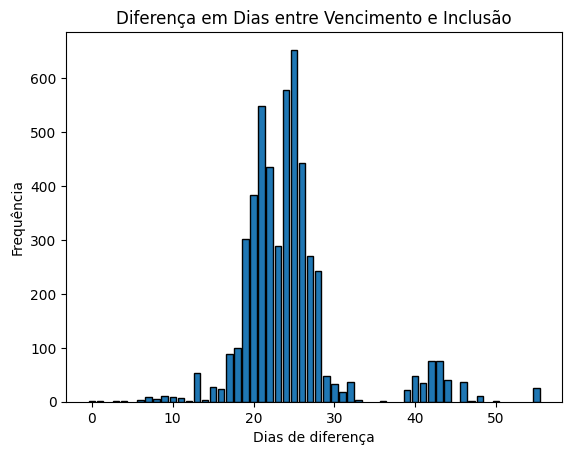

In [15]:


# Gráfico de barras
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Dias de diferença")
plt.ylabel("Frequência")
plt.show()


### Intervalo de Dias de boletos pagos

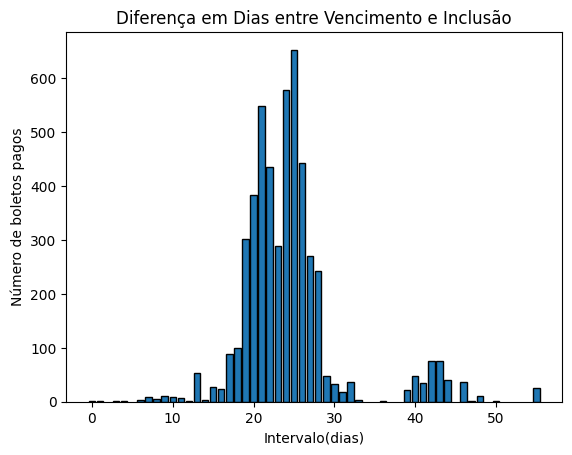

In [16]:

# Gráfico de barras
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos pagos")
plt.show()

### Intervalo de Dias de boletos não pagos

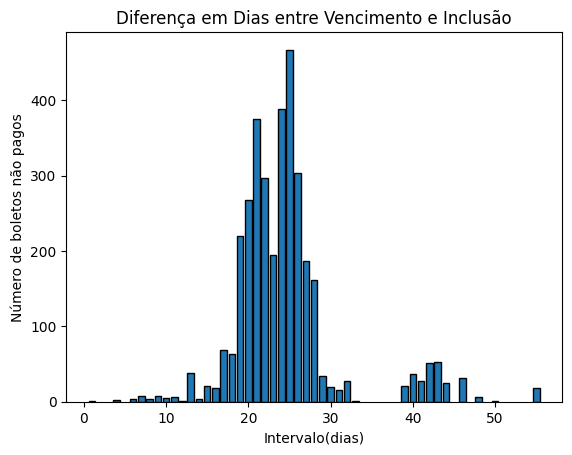

In [17]:


## Pegando intervalo de datas de inclusão e vencimento entre boletos pagos
dataVen = boletosPagos['data_vencto']
dataInc = boletosPagos['data_inclusao']
Datas = (dataVen - dataInc).dt.days
TipoData = Datas.value_counts()
TipoData = TipoData.sort_index()

# Gráfico de barras
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos não pagos")
plt.show()

### Quantidade de Acessos x Número de boletos pagos

C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\2728184055.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  boletosPagos['qtd_acessos_pagador'] = boletosPagos['qtd_acessos_pagador'].replace('\\N', 0)


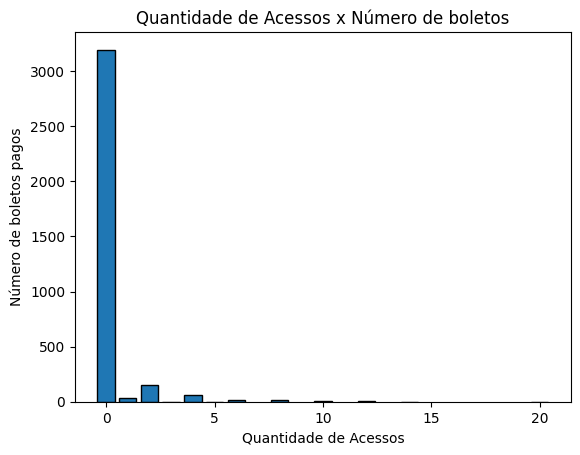

In [18]:

boletosPagos = TabelaAtual[(TabelaAtual['status_num'].isin([2]))]
boletosPagos['qtd_acessos_pagador'] = boletosPagos['qtd_acessos_pagador'].replace('\\N', 0) 
boletosPagos = boletosPagos[~boletosPagos.apply(lambda row: row.astype(str).str.contains(r'\\N').any(), axis=1)]

quantAcessos = boletosPagos['qtd_acessos_pagador'].astype(int) 
quantAcessos = quantAcessos.value_counts()
quantAcessos = quantAcessos.sort_index()

 # Gráfico de barras 
plt.bar(quantAcessos.index, quantAcessos.values, edgecolor="black")
plt.title("Quantidade de Acessos x Número de boletos") 
plt.xlabel("Quantidade de Acessos") 
plt.ylabel("Número de boletos pagos") 
plt.show()

### Quantidade de Acessos x Número de boletos não pagos

qtd_acessos_pagador
1      2
2     20
4      4
5      1
6      1
8      1
15     1
Name: count, dtype: int64


C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\1564395264.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  boletosNaoPagos['qtd_acessos_pagador'] = boletosNaoPagos['qtd_acessos_pagador'].replace('\\N', 0)


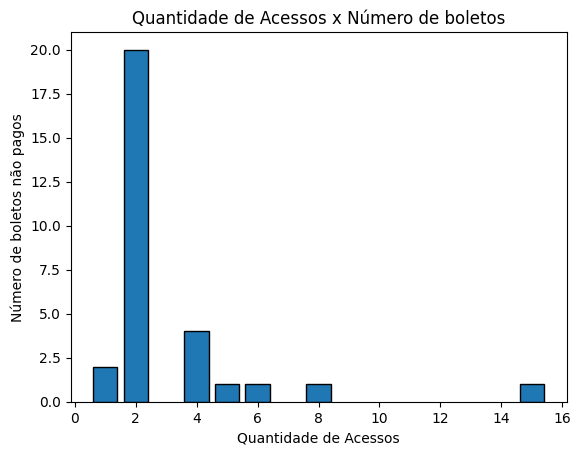

In [19]:

boletosNaoPagos = TabelaAtual[(TabelaAtual['status_num'].isin([0, 1]))]
boletosNaoPagos['qtd_acessos_pagador'] = boletosNaoPagos['qtd_acessos_pagador'].replace('\\N', 0) 
boletosNaoPagos = boletosNaoPagos[boletosNaoPagos['qtd_acessos_pagador'] != 0]

quantAcessos = boletosNaoPagos['qtd_acessos_pagador'].astype(int) 
quantAcessos = quantAcessos.value_counts()
quantAcessos = quantAcessos.sort_index()
print(quantAcessos)
 # Gráfico de barras 
plt.bar(quantAcessos.index, quantAcessos.values, edgecolor="black")
plt.title("Quantidade de Acessos x Número de boletos") 
plt.xlabel("Quantidade de Acessos") 
plt.ylabel("Número de boletos não pagos") 
plt.show()

### Pagadores por mês

**Hipótese**: O período do ano influência na média de pagamentos.
 Verificar se o mês influência no pagamento de boletos.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\1060069100.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\1060069100.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()


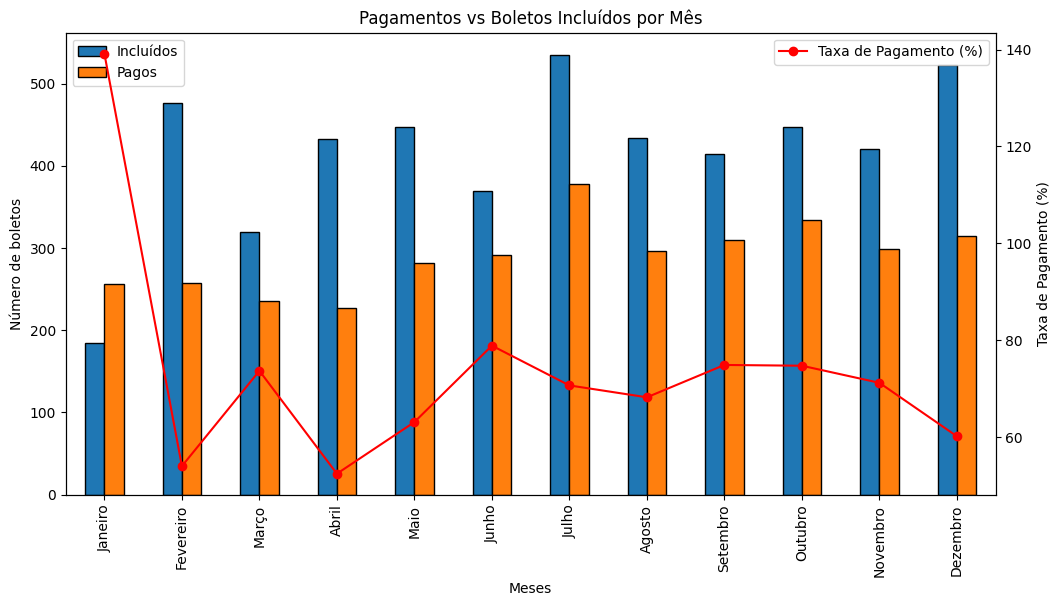

In [20]:


TabelaAtual['mes_pag'] = pd.Categorical(TabelaAtual['mes_pag'], categories=ordem_meses, ordered=True)
TabelaAtual['mes_inclusao'] = pd.Categorical(TabelaAtual['mes_inclusao'], categories=ordem_meses, ordered=True)

# Agrupamento
boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()

# Unir em dataframe
df_mes = pd.concat([boletos_incluidos, boletos_pagos], axis=1)
df_mes.columns = ['Incluídos', 'Pagos']
df_mes = df_mes.fillna(0)

# Taxa de pagamento
df_mes['Taxa'] = (df_mes['Pagos'] / df_mes['Incluídos']) * 100

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

df_mes[['Incluídos', 'Pagos']].plot(kind='bar', ax=ax1, edgecolor="black")
ax1.set_ylabel("Número de boletos")
ax1.set_xlabel("Meses")
ax1.set_title("Pagamentos vs Boletos Incluídos por Mês")

# Eixo secundário
ax2 = ax1.twinx()
ax2.plot(df_mes.index, df_mes['Taxa'], color="red", marker="o", label="Taxa de Pagamento (%)")
ax2.set_ylabel("Taxa de Pagamento (%)")

# Legendas
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

    

#### Dias necessários para pagar após inclusão

**Hipótese**: Verificar em quanto tempo os boletos são pagos.


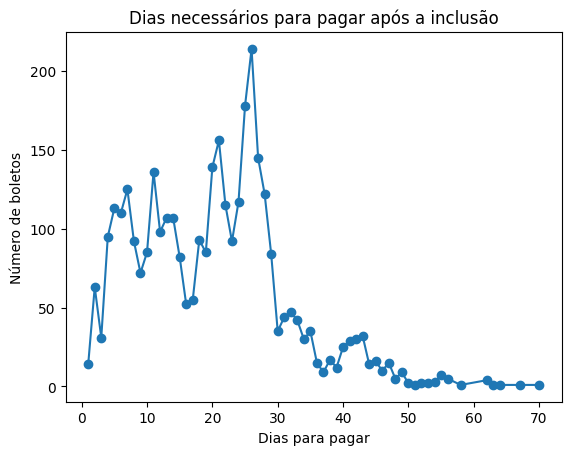

In [21]:



    # Gráfico de barras
plt.plot(DiasParaPagar.index, DiasParaPagar.values, marker="o")
plt.title("Dias necessários para pagar após a inclusão")
plt.xlabel("Dias para pagar")
plt.ylabel("Número de boletos")
plt.show()


### Dias para Pagar x Valor do Boleto

**Hipótese:** Boletos mais caros demoram mais para serem pagos.
<br>

**Objetivo:** Verificar se boletos mais caros demoram mais para serem pagos

C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\3912009524.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')


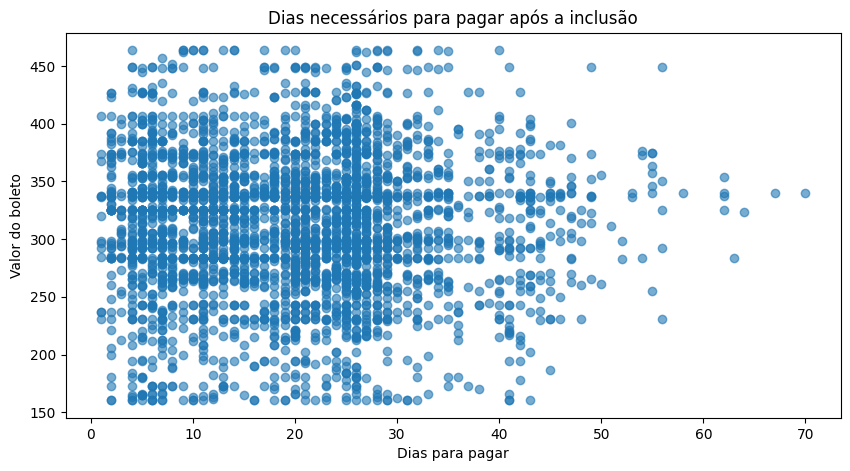

In [22]:
DiasParaPagar = TabelaAtual[TabelaAtual['dias_para_pagar'] > 0] 
DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
plt.figure(figsize=(10,5)) 
plt.scatter(DiasParaPagar['dias_para_pagar'], DiasParaPagar['vl_boleto'], alpha=0.6, marker="o") 
plt.title("Dias necessários para pagar após a inclusão") 
plt.xlabel("Dias para pagar") 
plt.ylabel("Valor do boleto") 
plt.show()

### Média de valor entre boletos pagos e não pagos

C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\3570382528.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')


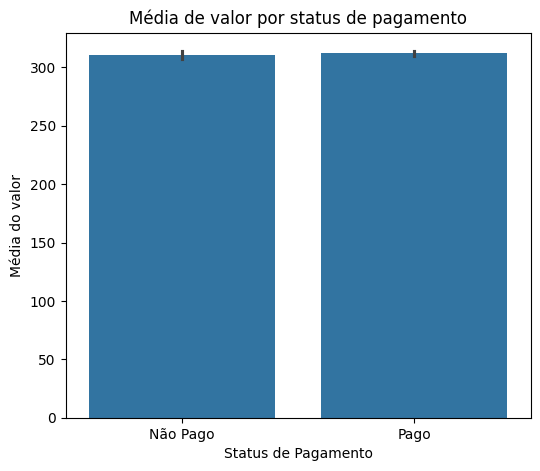

In [23]:

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
TabelaAtual['pago/n'] = TabelaAtual['status_num'].map(mapping)

TabelaAtual['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="vl_boleto", data=TabelaAtual, estimator="mean")

plt.title("Média de valor por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média do valor")
plt.show()

### Média de acessos entre boletos pagos e não pagos

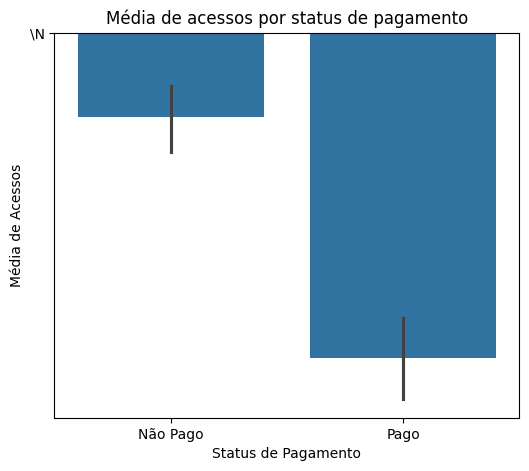

In [24]:
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="qtd_acessos_pagador", data=TabelaAtual, estimator="mean")

plt.title("Média de acessos por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média de Acessos")
plt.show()

### Valores dos boletos

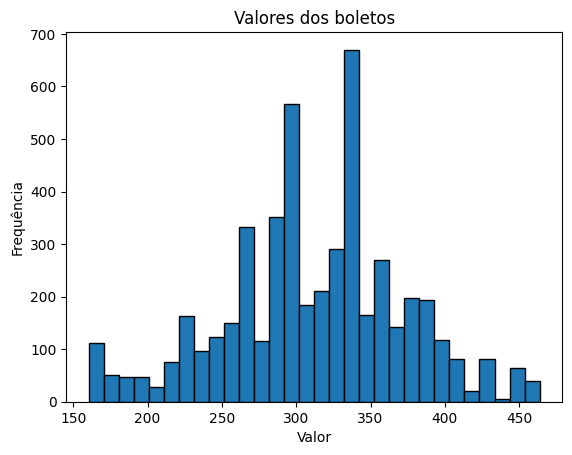

In [25]:
vBoleto = TabelaAtual['vl_boleto'].value_counts().sort_index()

plt.hist(TabelaAtual['vl_boleto'], bins=30, edgecolor="black")

plt.title("Valores dos boletos")
plt.xlabel("Valor")
plt.ylabel("Frequência")
plt.show()

### Valor dos boletos pagos

C:\Users\Inteli\AppData\Local\Temp\ipykernel_32128\1235095777.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')


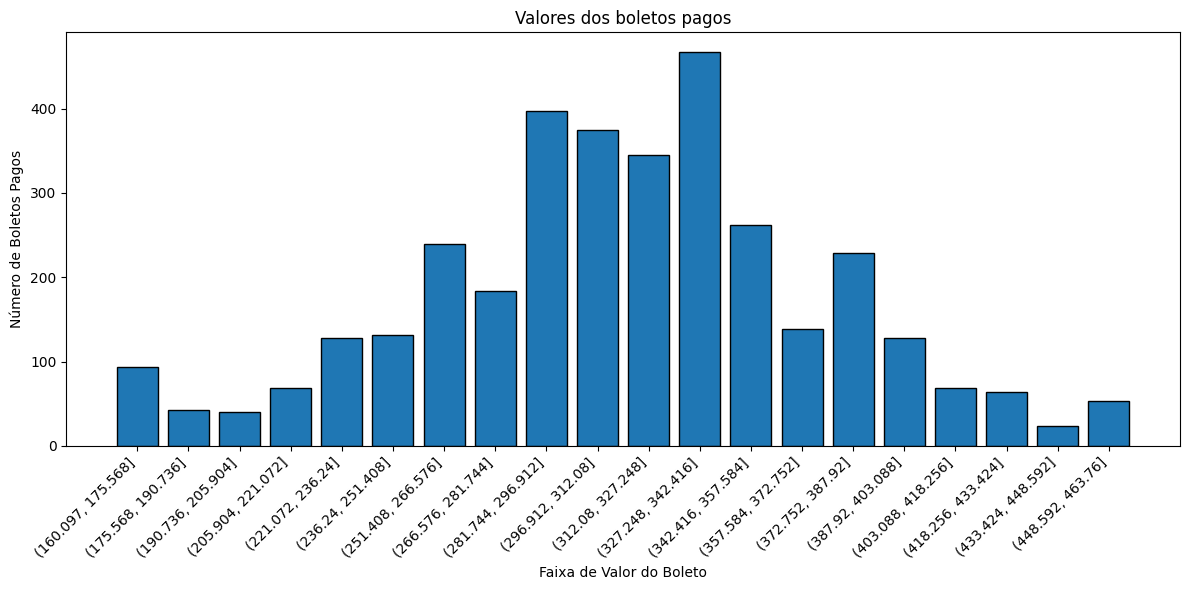

In [26]:
boletosPagos = TabelaAtual[TabelaAtual['status_num'] == 2]

boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')

# Remover linhas que ficaram NaN (eram inválidas)
boletosPagos = boletosPagos.dropna(subset=['vl_boleto'])

# Cria as faixas
bins = 20
boletosPagos['faixa_boleto'] = pd.cut(boletosPagos['vl_boleto'], bins=bins)

# Conta por faixa
vBoletoPagosGrouped = boletosPagos['faixa_boleto'].value_counts().sort_index()

# Gráfico
fig, ax = plt.subplots(figsize=(12,6))
ax.bar(vBoletoPagosGrouped.index.astype(str), vBoletoPagosGrouped.values, edgecolor="black")

ax.set_title("Valores dos boletos pagos")
ax.set_xlabel("Faixa de Valor do Boleto")
ax.set_ylabel("Número de Boletos Pagos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

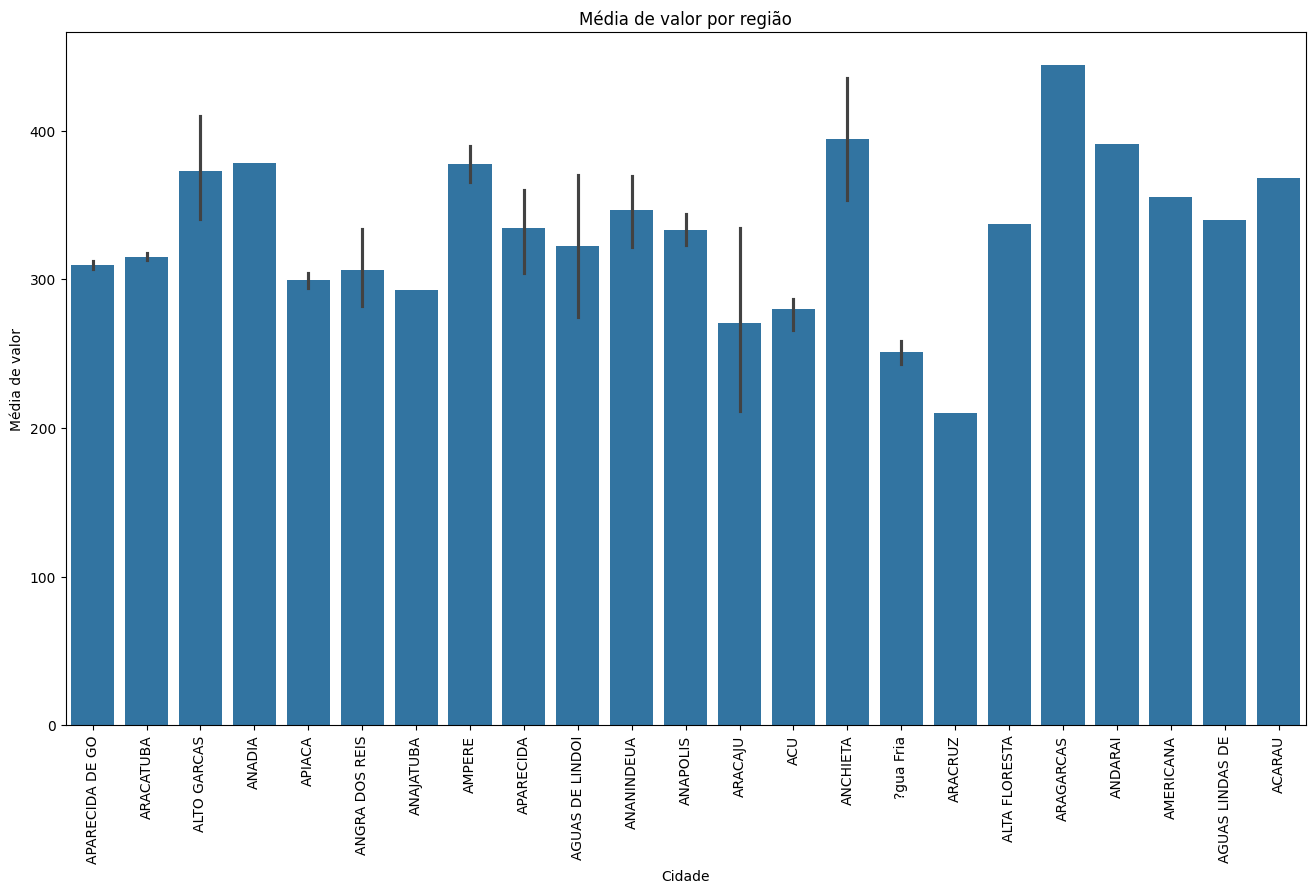

In [27]:


numeroPorCidade = TabelaAtual['pagador_cidade'].value_counts().sort_index()

plt.figure(figsize=(16,9))
sns.barplot(x="pagador_cidade", y="vl_boleto", data=TabelaAtual, estimator="mean")
plt.xticks(rotation=90)
plt.title("Média de valor por região")
plt.xlabel("Cidade")
plt.ylabel("Média de valor")
plt.show()

In [28]:


media = TabelaAtual['vl_boleto'].mean()
Multa = TabelaAtual[TabelaAtual['juros'] > 0]
NãoMultado = TabelaAtual[TabelaAtual['juros'] == 0]
Verif = NãoMultado['pago/n'].value_counts(normalize=True) * 100
Verif2 = Multa['pago/n'].value_counts(normalize=True) * 100
print(Verif2)


pago/n
Pago        69.58
Não Pago    30.42
Name: proportion, dtype: float64
